# 06 · 精确归因 vs 采样归因（TreeSHAP 双路径对照）

本项目库内的 SHAP 归因有两条估计路径，`shap_explain(..., method="auto")` 按模型选择：

| 路径 | 触发条件 | 解释对象 | 是否使用传入背景 | 声明字段 |
|---|---|---|---|---|
| 精确解 | xgboost / lightgbm（库自带 `pred_contribs` / `pred_contrib`） | 模型 margin（分类=目标类对数几率，回归=预测值） | 否，基线值取模型内部训练集期望 | `ShapResult.method="exact"` |
| 采样近似 | 其余全部模型（sklearn 森林与 boosting、线性、`LinearSVC`、MLP、自研网络） | 目标类概率 $P(y=1)$ | 是，背景行显式边际化 | `ShapResult.method="kernel"` |

本笔记本给出四组可复核读数：**路由**、**效率恒等式**、**与开源精确实现的对拍**、**每样本成本**。
对照的数学依据见 `py/MATH_PRINCIPLES.md` §1.2 与第六章对照表第 3 行，缺陷登记见 8.23。


In [1]:
# --- bootstrap：让 trustoran 可导入（与 05 同一写法） ---
import os, sys, time, warnings
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
warnings.filterwarnings("ignore")

REPO = os.path.abspath(os.path.join(os.getcwd(), ".."))
if not os.path.isdir(os.path.join(REPO, "py", "trustoran")):
    REPO = os.getcwd()
sys.path.insert(0, os.path.join(REPO, "py"))

%matplotlib inline
import numpy as np
import pandas as pd
import shap
from IPython.display import display

from trustoran.data import build_dataset, train_test_split_dataset
from trustoran.data.base import TaskType
from trustoran.models import make_model
from trustoran.trust import explainability as EX

SEED = 42
DATASET = "cci_a1sd_binary"
TARGET_CLASS = 1
print("repo   ", REPO)
print("shap   ", shap.__version__)


repo    E:\可信AI
shap    0.53.0


## 1 · 数据与模型

同一份训练/测试切分上装三个模型：xgboost（有原生精确路径）、lightgbm（有）、random_forest 与 mlp（无）。


In [2]:
ds = build_dataset(DATASET, max_rows=2000, seed=SEED)
sp = train_test_split_dataset(ds, test_size=0.3, seed=SEED)
task = sp.train.task
Xtr, ytr = np.asarray(sp.X_train, float), np.asarray(sp.y_train, int)
Xexp = np.asarray(sp.X_test, float)[:24]
bg = Xtr[:40]
d = Xtr.shape[1]
print("train", Xtr.shape, "test", np.asarray(sp.X_test).shape, "d=", d,
      "classes", sp.train.class_names)

models = {}
for key in ("xgboost", "lightgbm", "random_forest", "mlp"):
    m = make_model(key, task, sp.feature_names, sp.train.class_names)
    m.fit(Xtr, ytr)
    models[key] = m
print("fitted:", ", ".join(models))


train (2800, 10) test (1200, 10) d= 10 classes ['Normal', 'Dos']


fitted: xgboost, lightgbm, random_forest, mlp


## 2 · 路由：`method="auto"` 选了哪条路

请求精确解而模型没有原生路径时，库抛 `ValueError`，不静默降级。


In [3]:
rows = []
for key, m in models.items():
    r = EX.shap_explain(m, Xexp, bg, target_class=TARGET_CLASS, seed=SEED)
    refused = ""
    if r.method != "exact":
        try:
            EX.shap_explain(m, Xexp, bg, target_class=TARGET_CLASS,
                            method="exact", seed=SEED)
            refused = "DID NOT RAISE"
        except ValueError as e:
            refused = "ValueError: " + str(e)[:46]
    rows.append({"model": key, "method": r.method, "target": r.target,
                 "efficiency_max_error": r.efficiency_max_error,
                 'request method="exact"': refused})
pd.DataFrame(rows)


,model,method,target,efficiency_max_error,"request method=""exact"""
0,xgboost,exact,margin of class 1,4.681162e-06,
1,lightgbm,exact,margin of class 1,4.440892e-14,
2,random_forest,kernel,P(class 1),NaN,ValueError: RandomForestClassifier has no exac...
3,mlp,kernel,P(class 1),NaN,ValueError: MLPClassifier has no exact contrib...


## 3 · 效率恒等式：`base + Σφ` 是否等于被解释的量

精确路径上这是外部可核验的读数（残差只应来自浮点累加）。
采样路径末尾做了重标定，残差按构造恒为 $0$，因此它只能证明实现自洽，不能证明归因正确——
所以两条路径分别用不同的判据。


In [4]:
exact_rows = []
for key in ("xgboost", "lightgbm"):
    m = models[key]
    r = EX.shap_explain(m, Xexp, bg, target_class=TARGET_CLASS, seed=SEED)
    phi, base, margin = m.native_contribs(Xexp, TARGET_CLASS)
    resid = np.asarray(base, float) + np.asarray(phi, float).sum(axis=1) - np.asarray(margin, float)
    scale = float(np.max(np.abs(margin))) or 1.0
    exact_rows.append({"model": key,
                       "max|base+sum(phi)-margin|": float(np.max(np.abs(resid))),
                       "max|margin|": scale,
                       "relative": float(np.max(np.abs(resid))) / scale})
pd.DataFrame(exact_rows)


,model,max|base+sum(phi)-margin|,max|margin|,relative
0,xgboost,4.681162e-06,7.621206,6.142285e-07
1,lightgbm,4.440892e-14,14.718426,3.017233e-15


In [5]:
samp_rows = []
for key in ("random_forest", "mlp"):
    m = models[key]
    r = EX.shap_explain(m, Xexp, bg, target_class=TARGET_CLASS, seed=SEED)
    fn = EX.make_model_fn(m, TARGET_CLASS)
    fv = fn(Xexp)
    resid = r.base_value + np.asarray(r.shap_values, float).sum(axis=1) - fv
    samp_rows.append({"model": key, "path": r.method,
                      "max|base+sum(phi)-f(x)|": float(np.max(np.abs(resid))),
                      "note": "rescaled => self-consistent only"})
pd.DataFrame(samp_rows)


,model,path,max|base+sum(phi)-f(x)|,note
0,random_forest,kernel,2.220446e-16,rescaled => self-consistent only
1,mlp,kernel,1.110223e-16,rescaled => self-consistent only


## 4 · 与开源精确实现对拍

两边运行的是同一个精确算法（TreeSHAP），因此预期是逐样本相同而不是"接近"。
`shap.TreeExplainer` 输出对二分类是 `(n, d)`、对多分类是 `(n, d, K)`（类在最后一轴），
`expected_value` 按类索引——切片方式写错会伪装成算法分歧，这里显式核对形状。


In [6]:
cmp_rows = []
for key in ("xgboost", "lightgbm"):
    m = models[key]
    ours = np.asarray(EX.shap_explain(m, Xexp, bg, target_class=TARGET_CLASS,
                                      seed=SEED).shap_values, float)
    expl = shap.TreeExplainer(m.estimator)
    try:
        vals, ev = expl.shap_values(Xexp), expl.expected_value
    except Exception:
        vals, ev = expl.shap_values(Xexp, check_additivity=False), expl.expected_value
    if isinstance(vals, list):
        vals = np.asarray(vals[-1] if key == "xgboost" else vals, float)
    vals = np.asarray(vals, float)
    if vals.ndim == 3:
        vals = vals[:, :, TARGET_CLASS]
    if vals.shape != ours.shape:
        cmp_rows.append({"model": key, "status": "shape mismatch %s vs %s" % (vals.shape, ours.shape)})
        continue
    cos = [float(np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-12))
           for a, b in zip(ours, vals)]
    ref = float(np.ravel(ev)[TARGET_CLASS]) if np.size(ev) > 1 else float(np.ravel(ev)[0])
    ours_base = EX.shap_explain(m, Xexp, bg, target_class=TARGET_CLASS, seed=SEED).base_value
    cmp_rows.append({"model": key, "rows": ours.shape[0],
                     "cos_mean": float(np.mean(cos)), "cos_min": float(np.min(cos)),
                     "max_abs_diff": float(np.max(np.abs(ours - vals))),
                     "base_diff": abs(ours_base - ref)})
pd.DataFrame(cmp_rows)


,model,rows,cos_mean,cos_min,max_abs_diff,base_diff
0,xgboost,24,1.0,1.0,0.0,0.0
1,lightgbm,24,1.0,1.0,0.0,0.0


## 5 · 每样本成本

同一个已训练 booster，精确路径 vs 自身的采样路径。计时随 CPU 争用波动，这里给当次实测值。


In [7]:
def per_sample(fn, n=40):
    t0 = time.perf_counter()
    fn(Xexp[:n])
    return (time.perf_counter() - t0) * 1000.0 / n


cost_rows = []
for key in ("xgboost", "lightgbm"):
    m = models[key]
    ms_exact = per_sample(lambda Z: EX.shap_explain(m, Z, bg, target_class=TARGET_CLASS,
                                                    method="exact", seed=SEED))
    ms_kernel = per_sample(lambda Z: EX.shap_explain(m, Z, bg, target_class=TARGET_CLASS,
                                                     method="kernel", seed=SEED))
    cost_rows.append({"model": key, "exact ms/sample": ms_exact,
                      "sampled ms/sample": ms_kernel,
                      "speedup": ms_kernel / ms_exact})
pd.DataFrame(cost_rows)


,model,exact ms/sample,sampled ms/sample,speedup
0,xgboost,0.032007,0.740290,23.128642
1,lightgbm,0.062653,0.989007,15.785603


## 6 · 两条路径的图与图题

图题里的 `[exact]` / `[sampled]` 标签与中文标题由 `trustoran/viz/labels.py` 翻译，
这里同时验证英→中→英往返能复原。


xgboost        Mean |SHAP| — margin of class 1 [exact] | zh=平均 |SHAP| — 类别 1 的对数几率 [精确解] | round_trip_ok=True
random_forest  Mean |SHAP| — P(class 1) [sampled] | zh=平均 |SHAP| — 类别 1 的概率 [采样近似] | round_trip_ok=True


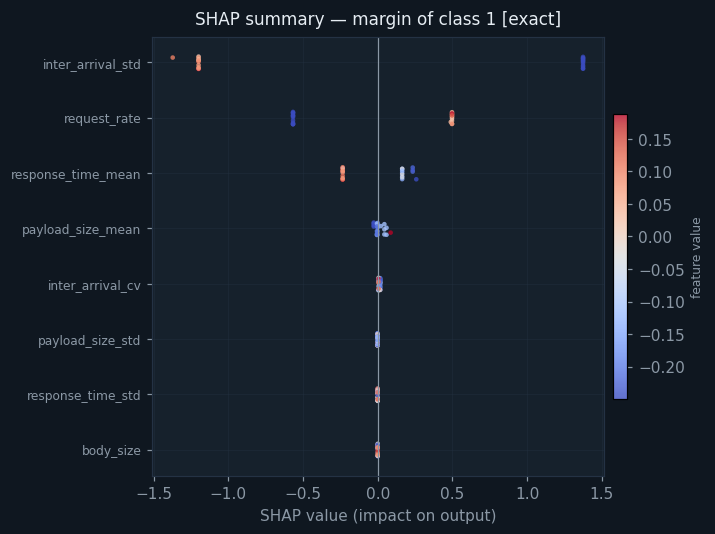

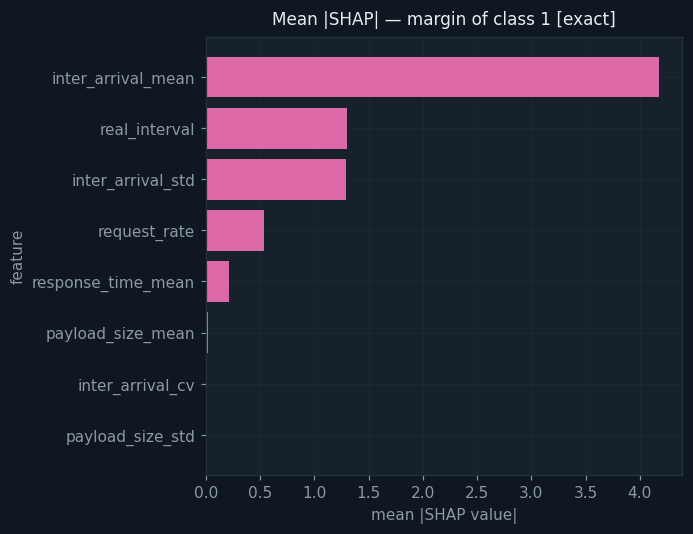

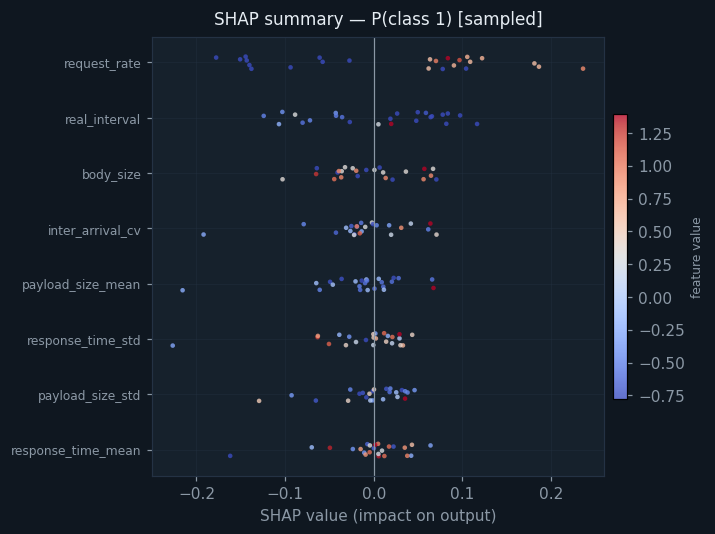

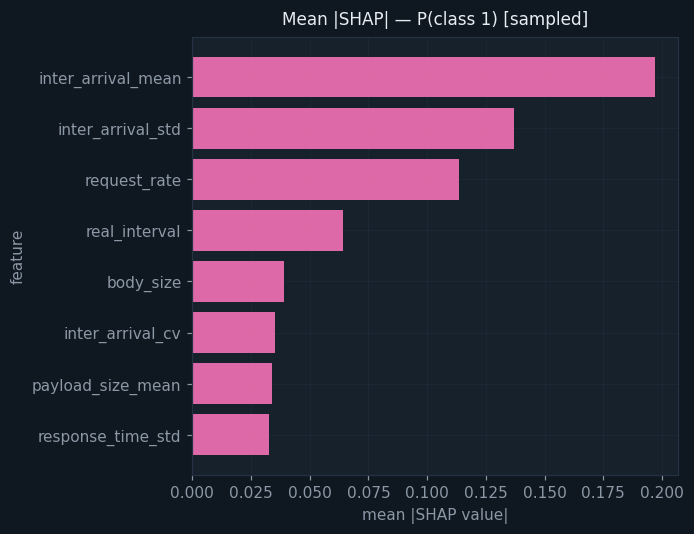

In [8]:
from trustoran.viz import plotting as PLT
from trustoran.viz import labels as L

figs = {}
for key in ("xgboost", "random_forest"):
    r = EX.shap_explain(models[key], Xexp, bg, target_class=TARGET_CLASS, seed=SEED)
    figs[key] = (PLT.fig_shap_summary(r, top=8), PLT.fig_shap_bar(r, top=8))


def title_of(fig):
    return fig.axes[0].get_title()


for key, (a, b) in figs.items():
    en0 = title_of(b)
    L.relabel_figure(b, "zh")
    zh = title_of(b)
    L.relabel_figure(b, "en")
    print("%-14s %s | zh=%s | round_trip_ok=%s" % (key, en0, zh, title_of(b) == en0))
display(*figs["xgboost"])
display(*figs["random_forest"])


## 结论

1. **路由可核验**：`method="auto"` 在 xgboost / lightgbm 上返回 `method="exact"`，在其余模型上返回 `method="kernel"`；
   对没有原生路径的模型请求 `method="exact"` 抛 `ValueError`。
2. **精确性可外部核验**：精确路径上 $\max\lvert\text{base}+\sum\varphi-\text{margin}\rvert$ 只来自浮点累加
   （lightgbm 在 $10^{-14}$ 量级、xgboost 在 $10^{-6}$ 量级，对应相对值 $10^{-15}$ 与 $10^{-7}$）。
   采样路径的重标定使残差恒为 $0$，因此采样路径的正确性由第 3 条与开源实现的对拍给出，不由自身残差给出。
3. **与开源精确实现逐样本相同**：`shap.TreeExplainer` 与库内精确解余弦为 $1.0000$、最大绝对差为 $0$。
4. **成本**：精确路径每样本耗时低于同一模型的采样路径一到两个数量级。
5. **口径**：精确路径解释 margin 且不使用传入背景，采样路径解释 $P(y=1)$。
   两者不做数值互换，只在各自的解释对象内比较；对外声称速度优势时，
   参照对象必须是同样在做采样近似的实现。
6. 全量验收脚本：`py/_research/exact_shap_check.py`（4 profile × 7 模型，100 行读数）与
   `py/_research/exact_engine_check.py`（管道 + 双语报告审计）。
